# Readmissão hospitalar a 30 dias em doentes com diabetes

**Enterprise Data Science Bootcamp 2026-27 — NOVA IMS**

> _Abstract (a escrever)._

Este notebook é a **carta** do projeto: segue a estrutura DSML e corre de ponta a ponta,
mas quase não tem lógica própria. Chama o código de `src/` e lê os resultados das bancadas
(`notebooks/01`–`06`) em `reports/` e `docs/figures/`.

**Índice**
- I. Enquadramento do problema
- II. Dados — 2.1 recolha · 2.2–2.3 exploração · 2.4–2.6 preparação
- III. Modelação — 3.1–3.3 baselines e modelos · 3.4–3.5 tuning e seleção · interpretação e fairness
- IV. Deployment

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

FIG = ROOT / "docs" / "figures"
REPORTS = ROOT / "reports"

# I. Enquadramento do problema

_Objetivo, utilizador (equipa de follow-up), métrica de negócio (recall@k)._

# II. Dados

## 2.1 Recolha

Diabetes 130-US hospitals (1999–2008), `data/raw/`. Preparação: `python -m src.data_preparation`.

## 2.2–2.3 Exploração

Detalhe em `notebooks/01_eda.ipynb` e [docs/eda_summary.md](docs/eda_summary.md).

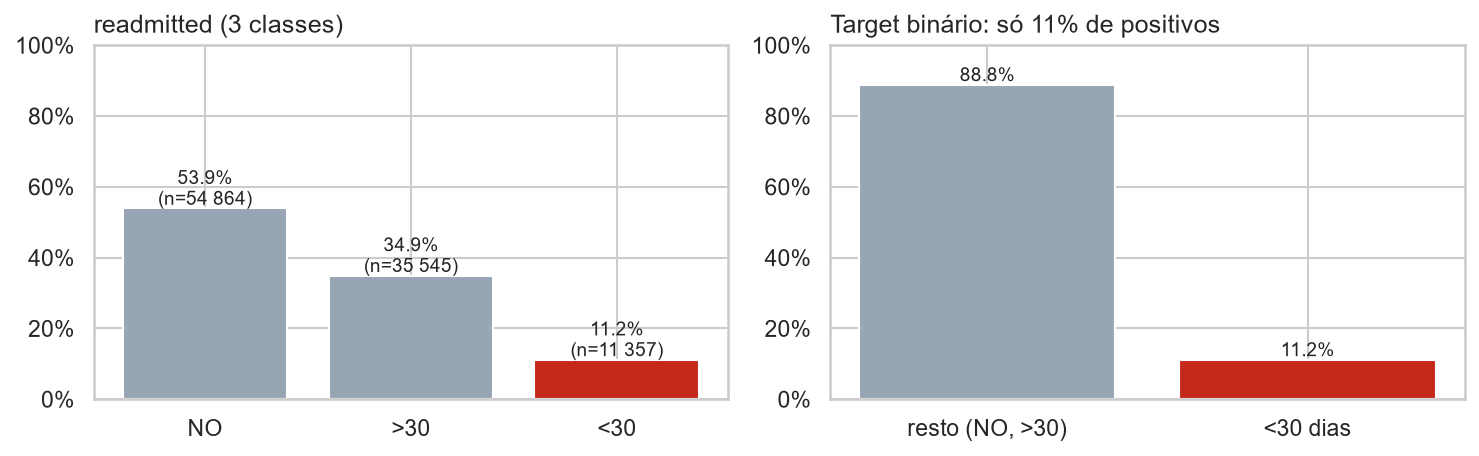

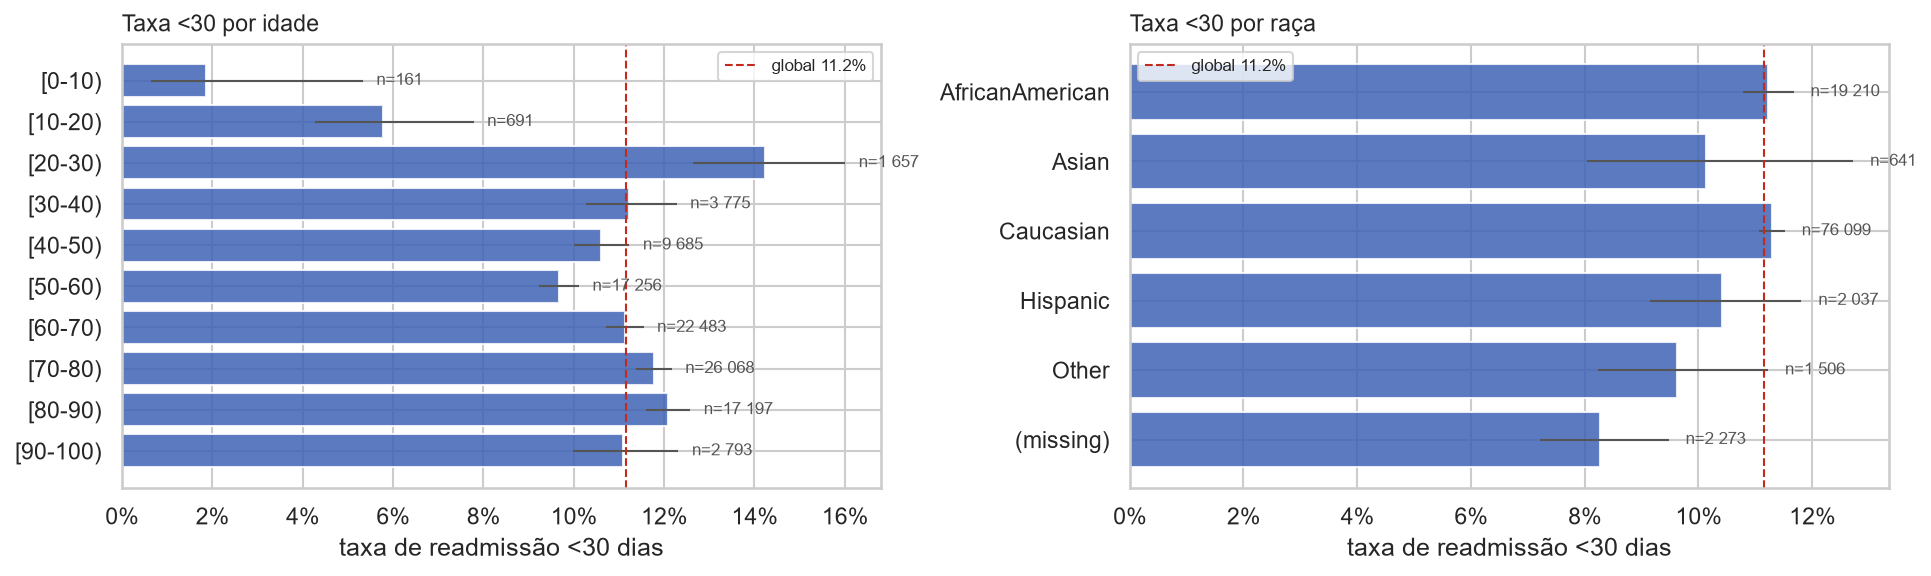

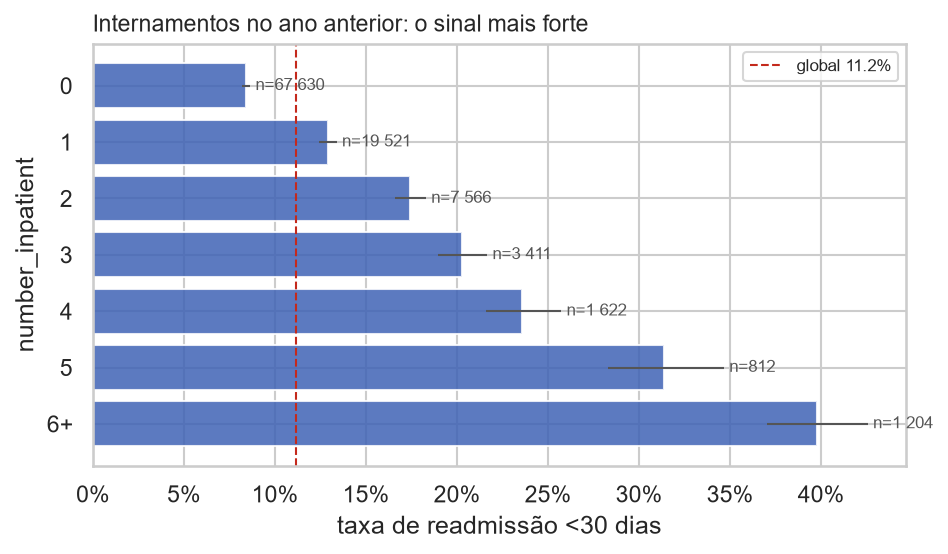

In [2]:
for f in ["01_target.png", "04_taxa_idade_raca.png", "05_taxa_number_inpatient.png"]:
    display(Image(FIG / f))

## 2.4–2.6 Preparação

Decisões D1–D16 em [docs/decisions.md](docs/decisions.md); verificação em `notebooks/02_preprocessing_check.ipynb`.

In [3]:
from src.pipeline import load_model_data

data = load_model_data()
print(f"Treino: {len(data.X_train)} encontros · teste: {len(data.X_test)} · {data.X_train.shape[1]} features")

Treino: 80041 encontros · teste: 20011 · 34 features


# III. Modelação

## 3.1–3.3 Baselines e modelos candidatos

Registo de todas as corridas (`notebooks/03`, `04`).

In [4]:
log = pd.read_csv(REPORTS / "experiments.csv")
cols = ["model", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "recall_at_10_mean", "recall_at_20_mean", "notes"]
log[cols].sort_values("pr_auc_mean", ascending=False).round(3)

,model,pr_auc_mean,pr_auc_std,roc_auc_mean,recall_at_10_mean,recall_at_20_mean,notes


## 3.4–3.5 Tuning, seleção e threshold

_Modelo escolhido, threshold pela capacidade de follow-up e avaliação final no teste (`notebooks/04`)._

## Interpretação e fairness

_SHAP e métricas por idade/raça/sexo (`notebooks/05`)._

# IV. Deployment

_Modelo em `models/model.joblib`; app Gradio em `src/app.py` (`python -m src.app`)._

# Conclusões e limitações

_Ex.: os `>30` contam como negativos (D6); teto de desempenho do dataset (ROC-AUC ≈ 0,65–0,70)._